# Transatlantic Sail: PDR Location and Sizing Calculations

**CUSail · Sails subsystem · Avram Dreyer · v5 baseline, 2026-09-26**

This notebook reproduces every first-pass number behind the transatlantic rigid-sail PDR sizing:
- the sail planform and section
- where the mast goes on the hull
- the loads handed to the keel, mast, bearing, hull and drive subsystems

Each step states the equation, the inputs and where they come from, then computes the result. The *reasoning* behind the choices (why a cambered plate, why 1.00 m from the bow, why 0.95 × 0.65 m) is in the companion document **`transatlantic_sail_design_decisions.md`**. Section numbers there point back to sections here.

**Baseline:** 8 % circular-arc cambered plate, pivot at 50 % chord (C-Star style), 0.95 m span × 0.65 m chord, mast ~1.00 m aft of the bow, self-locking worm drive. The NACA 0015 foil alternative is in Appendix A.

### How to read the source tags
Every input carries a tag. The full list is in Section 15 (References).

| Tag | Meaning |
|---|---|
| **[M]** | Measured from team CAD or team documents |
| **[L1]…[L12]** | Literature or standard reference |
| **[T]** | Team placeholder from another subsystem (will change) |
| **[A]** | Engineering assumption / judgment. **Verify before CDR** |

### Conventions
- SI units throughout. 1 kn = 0.5144 m/s.
- **x** runs aft from the bow plane (CAD convention; hull spans x = 0.05–2.00 m).
- **z** heights are measured from the 25 kg design waterline (WL) unless labelled "CAD z".
- Loads are **limit** loads unless marked **ult** (ultimate = 1.5 × limit).

### Files this notebook uses (same folder)
- `hull_hydrostatics_from_cad.py`: hull section table read from `Transatlantic Hull Shell.SLDPRT` (9/14)
- `transatlantic_trade_sweep.py`: heeled-hull (GZ) integration; cached in `_trade_sweep_Bcurves.npz`
- `transatlantic_sail_sizing.py`: the original sizing script, used in Section 14 as a cross-check

In [1]:
import math, numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import hull_hydrostatics_from_cad as hh      # CAD hull sections [M]
import transatlantic_trade_sweep as ts       # heeled-hull GZ integration (uses hh)

def table(rows, header):
    # Render a list of rows as a Markdown table.
    s = "| " + " | ".join(header) + " |\n|" + "---|"*len(header) + "\n"
    s += "\n".join("| " + " | ".join(str(c) for c in r) + " |" for r in rows)
    display(Markdown(s))

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

## 1. Constants and inputs

### 1.1 Physical constants

In [2]:
g      = 9.81      # m/s^2
rho_a  = 1.225     # kg/m^3, ISA sea-level air [L1]
rho_w  = 1025.0    # kg/m^3, seawater [L1]
kn     = 0.5144    # m/s per knot

### 1.2 Environment (Design Decisions §1)
Wind ranges follow the Beaufort scale [L2]. Bft 6 = 22–27 kn, so 27 kn is the top of the sailable range. 50 kn is the survival design wind: the upper bound of the team's 40–50 kn target.

In [3]:
V_cruise   = 12.0   # kn, typical trade-wind cruise (Bft 4)            [A]
V_sail_max = 27.0   # kn, top of Bft 6: last "full power" case          [L2]
V_survival = 50.0   # kn, survival design wind (Design Decisions §1)             [team decision]
SF         = 1.5    # ultimate / limit                                  [A] (standard aerospace/marine first-pass factor)

### 1.3 Hull, keel and rudder
Hull values come straight from the CAD section table (Section 2 recomputes them). The keel and rudder have not been drawn yet, so their values are placeholders from the owning subsystems.

In [4]:
disp_kg    = 25.0     # kg design displacement (Hull review: 25 kg, "subject to change")   [T]
M_OTHER    = 15.39    # kg hull + systems (everything except rig and ballast)             [T] = 25 - 7 - 2.61
Z_OTHER    = 0.02     # m, CG height of hull + systems above WL                           [A]
shell_t    = 0.003    # m hull skin thickness                                              [A]
bottom_clr = 0.025    # m heel bearing above inside of hull bottom                         [A]
bulb_kg, bulb_z = 7.0, -0.28   # keel bulb mass and CG height                              [T] Luis, rough
CLR_x, CLR_depth = 1.15, 0.15  # m from bow, m below WL; range 1.12-1.23                   [A] (not in CAD yet)
rud = dict(x=2.06, A=0.10*0.17, CL_max=0.8, V=1.2)  # rudder 0.10 x 0.17 m, boat 1.2 m/s    [T] Megan placeholder; CL_max [L8]

### 1.4 Sail design variables (the things this notebook sizes)

In [5]:
span, chord = 0.95, 0.65   # m  (Design Decisions §4)
camber      = 0.08         # f/c, 8 % circular arc (Design Decisions §3)
pivot       = 0.50         # pivot as fraction of chord from LE (Design Decisions §3)
foot_gap    = 0.10         # m sail foot above deck (clears deck hardware; keep-out height)   [A]
mast_top_below_tip = 0.10  # m                                                                [A]
mast_x      = 1.00         # m from bow (Design Decisions §6, derived in Section 5)

### 1.5 Plate aerodynamic coefficients
These are **literature-level estimates**, not measurements. The two most important numbers (the pitching-moment coefficient and the CP location) set the drive torque, which is the binding constraint. They are the first thing to verify by CFD or a bench test.

| Symbol | Value | Basis |
|---|---|---|
| C_F,max | 1.3 | Max resultant force coefficient of a ~8–10 % cambered thin plate at Re ~ 10⁵: Bruining curved-plate data [L4]; Pelletier & Mueller low-AR cambered plates [L5]. [A] reduced slightly for AR 1.46. |
| C_F,broad | 1.35 | Flat plate normal to flow, AR 1–2: C_D ≈ 1.17–1.2 [L6]. Concave (cup) side facing the wind raises this, so 1.35 is used. |
| C_m0 | −π f/c = −0.25 | Thin-airfoil theory for a circular-arc (parabolic) camber line [L3]; see 4.2 |
| x_cp (small AoA) | 0.30 c | Quarter chord from thin-airfoil theory, moved aft by the camber couple at operating C_L [L3]. [A] |
| x_cp (broadside) | 0.50 c | Symmetry at 90° [L6] |
| C_D0 | 0.06 | Thin cambered plate profile drag at Re ~2×10⁵ [L5], [A] |

In [6]:
CF_max, CF_broad = 1.3, 1.35
Cm0      = -math.pi*camber        # about the quarter chord, from thin-airfoil theory [L3]
cp_small, cp_stall, cp_broad = 0.30, 0.30, 0.50
CD0      = 0.06
e_osw    = 0.9                    # span efficiency for induced drag, rectangular planform [A]
gust_yaw = 10.0                   # deg, gust / yaw misalignment when feathered in survival [A]
print(f"Cm0 = {Cm0:.3f}")

Cm0 = -0.251


### 1.6 Structure, mass and drive inputs

In [7]:
# mast: roll-wrapped CF tube
mast_OD, mast_wall = 0.042, 0.0025   # m                                         [A]
E_mast      = 100e9                  # Pa, axial modulus of roll-wrapped CF tube   [A] (typ. 70-135 GPa; confirm with vendor)
sigma_allow = 400e6                  # Pa, allowable flexural stress               [A] (conservative vs typ. vendor data)
rho_cf      = 1600                   # kg/m^3 CFRP                                 [L7]
# plate: foam-core sandwich
skin_areal  = 0.60                   # kg/m^2 per face (2-ply glass or 1-ply carbon + resin) [A]
foam_rho, core_t = 60.0, 0.010       # kg/m^3 (Divinycell H60 class), m            [L12]
rib_frac    = 0.15                   # ribs/spine/bond mass as fraction of skins   [A]
hardware_kg = 0.5                    # hub, tip cap, fasteners                     [A]
# drive
slew_deg_s, eta_drive, standby_W = 18.0, 0.30, 0.10   # deg/s (180 deg in 10 s), overall efficiency, standby W  [A]
trims_per_day, trim_deg, tacks_per_day = 144, 10, 10  # every 10 min, 10 deg; 10 gybes/tacks per day [A]

## 2. Hull hydrostatics (from CAD)

The hull shell CAD has 14 loft stations. Each station is a flat deck, a slightly tumblehome side line, a 75 mm bilge radius and a circular-arc bottom. `hull_hydrostatics_from_cad.py` rebuilds each section, clips it at a trial waterline and integrates along x with the trapezoidal rule.

**Equations** (standard hydrostatics [L8]):

$$\nabla = \int A_s(x)\,dx, \qquad \Delta = \rho_w \nabla$$

$$LCB = \frac{\int x\,A_s\,dx}{\nabla}, \qquad KB = \frac{\int z_{c}(x)\,A_s\,dx}{\nabla}$$

$$BM = \frac{I_T}{\nabla}, \qquad I_T = \int \frac{B_{wl}(x)^3}{12}\,dx, \qquad KM = KB + BM$$

where $A_s$ is the immersed section area, $z_c$ its centroid height and $B_{wl}$ the waterline beam. The waterline is found by bisection so that $\rho_w\nabla$ equals the displacement.

In [8]:
zk_min = min(hh.section(x)[1] for x in hh.xs)          # canoe-body keel, CAD z
z_wl   = hh.waterline(disp_kg)                          # CAD z of WL at 25 kg
H      = hh.hyd(z_wl)
T_canoe   = z_wl - zk_min
deck_mid  = hh.S[1.10][0][1]                            # flat midbody deck, CAD z
freeboard = deck_mid - z_wl
KB = H['VCB'] - z_wl; BM = H['BM']; KM_wl = KB + BM
table([
 ["Waterline (CAD z)", f"{z_wl:+.4f} m", "bisection on displacement"],
 ["Canoe draft T", f"{T_canoe:.4f} m", "WL - keel"],
 ["Freeboard at midbody (x 0.95-1.10)", f"{freeboard:.3f} m", "deck z 0.150 - WL"],
 ["LCB", f"{H['LCB']:.3f} m from bow", ""],
 ["KB (wrt WL)", f"{KB:+.3f} m", ""],
 ["BM = I_T / V", f"{BM:.3f} m", ""],
 ["**KM (wrt WL)**", f"**{KM_wl:+.3f} m**", "KB + BM"],
 ["Waterline beam / waterplane area", f"{H['Bwl']:.3f} m / {H['Awp']:.3f} m²", ""],
 ["Canoe-body lateral area, centroid", f"{H['lat']:.4f} m² @ x = {H['latx']:.3f} m", "hull only; keel adds more"],
], ["Quantity", "Value", "Note"])

| Quantity | Value | Note |
|---|---|---|
| Waterline (CAD z) | -0.0303 m | bisection on displacement |
| Canoe draft T | 0.0732 m | WL - keel |
| Freeboard at midbody (x 0.95-1.10) | 0.180 m | deck z 0.150 - WL |
| LCB | 1.130 m from bow |  |
| KB (wrt WL) | -0.026 m |  |
| BM = I_T / V | 0.283 m |  |
| **KM (wrt WL)** | **+0.257 m** | KB + BM |
| Waterline beam / waterplane area | 0.431 m / 0.600 m² |  |
| Canoe-body lateral area, centroid | 0.0972 m² @ x = 1.140 m | hull only; keel adds more |

Depth and half-beam by station. These bound where the mast and drive can physically go (Section 5.3).

In [9]:
rows=[]
for x in hh.xs:
    poly, zk, _, _ = hh.section(x)
    rows.append([f"{x:.2f}", f"{hh.S[x][0][1]-zk:.3f}", f"{hh.S[x][1][0]:.3f}"])
table(rows, ["x from bow (m)", "keel-to-deck depth (m)", "max half-beam (m)"])

| x from bow (m) | keel-to-deck depth (m) | max half-beam (m) |
|---|---|---|
| 0.05 | 0.232 | 0.018 |
| 0.10 | 0.231 | 0.037 |
| 0.20 | 0.231 | 0.075 |
| 0.35 | 0.239 | 0.128 |
| 0.50 | 0.245 | 0.178 |
| 0.65 | 0.249 | 0.216 |
| 0.80 | 0.254 | 0.240 |
| 0.95 | 0.254 | 0.244 |
| 1.10 | 0.254 | 0.244 |
| 1.25 | 0.253 | 0.239 |
| 1.40 | 0.255 | 0.230 |
| 1.55 | 0.254 | 0.211 |
| 1.70 | 0.251 | 0.188 |
| 1.85 | 0.248 | 0.169 |

## 3. Sail geometry

### 3.1 Planform
$$A = s\,c, \qquad AR = \frac{s}{c}$$

### 3.2 Circular-arc section
For camber ratio $f/c$, the sagitta is $f = (f/c)\,c$. The arc radius follows from the chord–sagitta relation for a circle:
$$R_{arc} = \frac{(c/2)^2 + f^2}{2f}$$
This is the radius of the mould or cylinder the plate is laid up on.

### 3.3 Sweep circle
The sail sweeps a circle on the deck whose radius is the longer of the two pivot-to-edge distances:
$$R_{sweep} = \max(a,\;1-a)\,c$$
where $a$ is the pivot position as a fraction of chord.

In [10]:
A  = span*chord
AR = span/chord
f  = camber*chord
R_arc   = ((chord/2)**2 + f**2)/(2*f)
R_sweep = max(pivot, 1-pivot)*chord
table([
 ["Area A", f"{A:.3f} m²"], ["Aspect ratio AR", f"{AR:.2f}"],
 ["Sagitta f", f"{f*1000:.0f} mm"], ["Arc radius R_arc", f"{R_arc:.3f} m"],
 ["Sweep radius / diameter", f"{R_sweep:.3f} m / {2*R_sweep:.2f} m"],
 ["Sweep circle on deck", f"x = {mast_x-R_sweep:.3f} to {mast_x+R_sweep:.3f} m"],
 ["SA/D = A / (disp/rho_w)^(2/3)", f"{A/((disp_kg/rho_w)**(2/3)):.1f}"],
], ["Quantity", "Value"])

| Quantity | Value |
|---|---|
| Area A | 0.617 m² |
| Aspect ratio AR | 1.46 |
| Sagitta f | 52 mm |
| Arc radius R_arc | 1.042 m |
| Sweep radius / diameter | 0.325 m / 0.65 m |
| Sweep circle on deck | x = 0.675 to 1.325 m |
| SA/D = A / (disp/rho_w)^(2/3) | 7.3 |

The last line is the sail-area/displacement ratio $SA/D = A/\nabla^{2/3}$ [L8]. At 7.3 it is deliberately low (cruising yachts are ~16–20, and the CUSail comp boat is ~17.7). This reflects the "survivability over speed" decision (Design Decisions §4.1).

## 4. Vertical stack and aerodynamic model

### 4.1 Heights above the waterline
The CE height assumes uniform spanwise loading on a rectangle (the centroid). Real loading drops at the tip and at the foot gap, so this is slightly high, which is conservative for heel and mast moment.

$$z_{deck} = \text{freeboard}, \quad z_{foot} = z_{deck} + g_{foot}, \quad z_{CE} = z_{foot} + s/2, \quad z_{tip} = z_{foot} + s$$

$$z_{heel} = -T + t_{shell} + c_{bottom}, \qquad L_{brg} = z_{deck} - z_{heel}$$

Two lever arms are used throughout:
- heeling arm (CE to CLR): $h_{heel} = z_{CE} + d_{CLR}$
- mast lever (CE to deck bearing): $h_{mast} = z_{CE} - z_{deck}$

In [11]:
z_deck = freeboard
z_foot = z_deck + foot_gap
z_CE   = z_foot + span/2
z_tip  = z_foot + span
z_heel = -T_canoe + shell_t + bottom_clr
L_brg  = z_deck - z_heel
h_heel = z_CE + CLR_depth
h_mast = z_CE - z_deck
table([
 ["Sail tip (air draft)", f"{z_tip:+.3f}"], ["Mast top", f"{z_tip-mast_top_below_tip:+.3f}"],
 ["**Centre of effort z_CE**", f"**{z_CE:+.3f}**"], ["Sail foot", f"{z_foot:+.3f}"],
 ["Deck / deck bearing", f"{z_deck:+.3f}"], ["Heel bearing", f"{z_heel:+.3f}"],
 ["Bearing spacing L_brg", f"{L_brg:.3f}"], ["Heeling arm h_heel (CE to CLR)", f"{h_heel:.3f}"],
 ["Mast lever h_mast (CE to deck)", f"{h_mast:.3f}"],
], ["Point", "Height above WL (m)"])

| Point | Height above WL (m) |
|---|---|
| Sail tip (air draft) | +1.230 |
| Mast top | +1.130 |
| **Centre of effort z_CE** | **+0.755** |
| Sail foot | +0.280 |
| Deck / deck bearing | +0.180 |
| Heel bearing | -0.045 |
| Bearing spacing L_brg | 0.226 |
| Heeling arm h_heel (CE to CLR) | 0.905 |
| Mast lever h_mast (CE to deck) | 0.575 |

### 4.2 Aerodynamic relations

**Dynamic pressure and force:**
$$q = \tfrac12 \rho_a V^2, \qquad F = q\,A\,C_F$$

**Finite-wing lift slope, Helmbold's low-aspect-ratio relation** [L3] (valid for AR < ~4, straight wings):
$$a = \frac{2\pi\,AR}{2 + \sqrt{AR^2 + 4}} \quad \text{per radian}$$

**Camber effects from thin-airfoil theory** [L3]. For a parabolic camber line $z = 4f\,x(c-x)/c^2$ (≈ circular arc at small camber), the Fourier coefficients are $A_1 = 4f/c$ and $A_2 = 0$, so
$$\alpha_{L=0} = -2\frac{f}{c}, \qquad C_{m,c/4} = \frac{\pi}{4}(A_2 - A_1) = -\pi\frac{f}{c}$$

**Induced drag** (used only for the feathered-in-a-gust case):
$$C_D = C_{D0} + \frac{C_L^2}{\pi e\,AR}, \qquad C_F = \sqrt{C_L^2 + C_D^2}$$

In [12]:
def q(v_kn): return 0.5*rho_a*(v_kn*kn)**2
a_slope = 2*math.pi*AR/(2+math.sqrt(AR**2+4))
alpha_L0 = -2*camber
CL_g = a_slope*math.radians(gust_yaw)
CF_feath = math.hypot(CL_g, CD0 + CL_g**2/(math.pi*e_osw*AR))
print(f"Helmbold lift slope a = {a_slope:.3f} /rad  ({a_slope*math.pi/180:.4f} /deg);  2D value would be 2π = {2*math.pi:.3f}")
print(f"Zero-lift angle = {math.degrees(alpha_L0):.1f} deg;  Cm_c/4 = {Cm0:.3f}")
print(f"Feathered with {gust_yaw:.0f} deg gust: CL = {CL_g:.3f}, CF = {CF_feath:.3f}")
for v in (8, V_cruise, 20, V_sail_max, V_survival): print(f"  q({v:>4.0f} kn) = {q(v):6.1f} Pa")

Helmbold lift slope a = 2.051 /rad  (0.0358 /deg);  2D value would be 2π = 6.283
Zero-lift angle = -9.2 deg;  Cm_c/4 = -0.251
Feathered with 10 deg gust: CL = 0.358, CF = 0.369
  q(   8 kn) =   10.4 Pa
  q(  12 kn) =   23.3 Pa
  q(  20 kn) =   64.8 Pa
  q(  27 kn) =  118.2 Pa
  q(  50 kn) =  405.2 Pa


### 4.3 Force-coefficient tables used for the balance model
Section 5 needs $C_L(\alpha)$ and $C_D(\alpha)$ over the full 0–90° range to trim the sail at every point of sail. These tables are the same ones used in the Transatlantic Rig Mockup. They are shaped from the curved-plate data in [L4] and [L5] and pinned to the endpoints above ($C_{L,max}$ ≈ 1.1 at ~25°, $C_D$ = 1.35 at 90°). **[A]: replace with CFD or wind-tunnel data when available.**

Centre of pressure: $x_{cp}/c = x_{cp,small} + (x_{cp,broad} - x_{cp,small})\sin\alpha$, measured from whichever edge faces the wind.

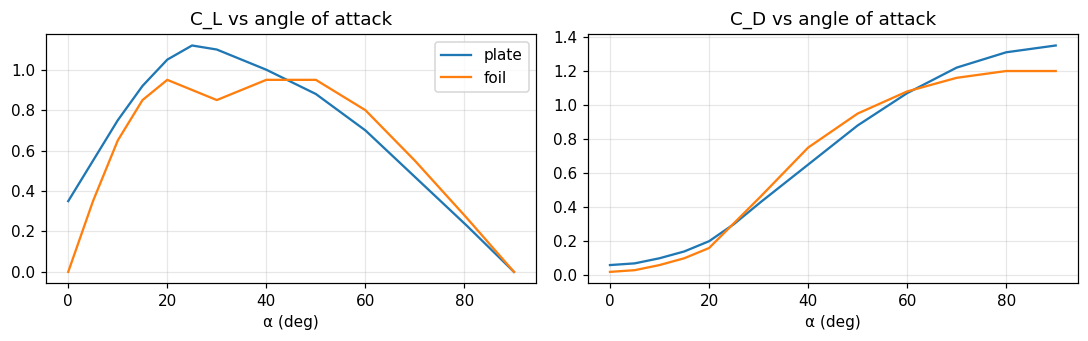

In [13]:
PLATE_CL = [(0,.35),(5,.55),(10,.75),(15,.92),(20,1.05),(25,1.12),(30,1.10),(40,1.00),(50,.88),(60,.70),(70,.47),(80,.24),(90,0)]
PLATE_CD = [(0,.06),(5,.07),(10,.10),(15,.14),(20,.20),(25,.30),(30,.42),(40,.65),(50,.88),(60,1.07),(70,1.22),(80,1.31),(90,1.35)]
FOIL_CL  = [(0,0),(5,.35),(10,.65),(15,.85),(20,.95),(25,.90),(30,.85),(40,.95),(50,.95),(60,.80),(70,.55),(80,.28),(90,0)]
FOIL_CD  = [(0,.02),(5,.03),(10,.06),(15,.10),(20,.16),(30,.45),(40,.75),(50,.95),(60,1.08),(70,1.16),(80,1.2),(90,1.2)]
interp = lambda tbl: (lambda a: float(np.interp(min(max(a,0),90), *zip(*tbl))))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
aa = np.linspace(0, 90, 181)
for tb, lab in ((PLATE_CL,'plate'),(FOIL_CL,'foil')): ax[0].plot(aa, [interp(tb)(x) for x in aa], label=lab)
for tb, lab in ((PLATE_CD,'plate'),(FOIL_CD,'foil')): ax[1].plot(aa, [interp(tb)(x) for x in aa], label=lab)
ax[0].set(title="C_L vs angle of attack", xlabel="α (deg)"); ax[1].set(title="C_D vs angle of attack", xlabel="α (deg)")
ax[0].legend(); plt.tight_layout(); plt.show()

## 5. Longitudinal mast position (Design Decisions §6)

Two conditions decide where the mast goes:
1. **Downwind directional stability.** Running before the trade winds, the sail force points along the boat. If the CE is *ahead* of the CLR, a yaw disturbance produces a restoring moment and the boat tracks by itself. If the CE is *behind*, the stern tries to lead and the rudder must correct constantly.
2. **Upwind rudder authority.** Moving the CE forward produces lee helm on a reach or close-hauled. The rudder must be able to cancel it with margin.

### 5.1 Model
For a sail rotated to angle δ (sail chord relative to the boat centreline) in apparent wind from angle β:
- The angle of attack is $\alpha = \arccos|\hat e\cdot\hat u|$, where $\hat e$ is the chord direction and $\hat u$ the flow direction.
- The CE lies on the chord at $x_{cp}(\alpha)$ from the upwind edge (Section 4.3).
- Lift acts perpendicular to the flow toward leeward; drag acts along the flow: $\vec F = qA\,(C_L\hat L + C_D\hat u)$.
- Driving force $= -F_x$; yaw moment about the CLR: $M_z = (x_{CE}-x_{CLR})F_y - y_{CE}F_x$.
- For the plate, if the concave side faces leeward (sail "backwards"), C_L is heavily penalised. The trim search therefore always finds the correct orientation.

At every apparent-wind angle the sail is trimmed for maximum drive (δ swept in 1° steps).

**Rudder capacity:**
$$M_{rud} = \tfrac12\rho_w V_b^2\,A_{rud}\,C_{L,max}\,(x_{rud} - x_{CLR})$$

In [14]:
def aero(delta, awa, aws, mastx, V=None):
    # Port of the Transatlantic Rig Mockup aero() for the plate (or foil if V given).
    V = V or dict(CL=interp(PLATE_CL), CD=interp(PLATE_CD), cpS=cp_small, cpB=cp_broad, pivot=pivot, plate=True)
    d, b = math.radians(delta), math.radians(awa)
    e = np.array([math.cos(d), math.sin(d)]); n = np.array([-math.sin(d), math.cos(d)])
    u = np.array([math.cos(b), -math.sin(b)])                    # flow direction (x aft, y stbd)
    eu, un = e@u, u@n
    alpha = math.degrees(math.acos(min(1, abs(eu))))
    uA, uB = -V['pivot']*chord, (1-V['pivot'])*chord
    uUp, uDn = (uA, uB) if uA*eu < uB*eu else (uB, uA)
    forward = (uUp == uA) if not V['plate'] else True
    CL, CD = V['CL'](alpha), V['CD'](alpha)
    if V['plate'] and not un > 0: CL = 0.55*CL - 0.3*math.cos(math.radians(alpha))   # concave side to leeward
    if not forward: CL *= 0.6; CD *= 1.1
    xcp = V['cpS'] + (V['cpB']-V['cpS'])*math.sin(math.radians(alpha))
    uCP = uUp + (uDn-uUp)*xcp
    ce = np.array([mastx, 0]) + uCP*e
    lee = (1 if un >= 0 else -1)*n
    L = np.array([-u[1], u[0]]);  L = L if L@lee >= 0 else -L
    F = q(aws)*A*(CL*L + CD*u)
    Mz = (ce[0]-CLR_x)*F[1] - ce[1]*F[0]
    return dict(alpha=alpha, ce=ce, F=F, drive=-F[0], Mz=Mz)

def trimmed(awa, aws, mastx, V=None):
    best = max(range(-180, 181), key=lambda dd: aero(dd, awa, aws, mastx, V)['drive'])
    return aero(best, awa, aws, mastx, V)

def helm_sweep(mastx, aws=V_cruise, V=None):
    out = []
    for awa in range(30, 181, 5):
        a = trimmed(awa, aws, mastx, V)
        helm = -a['Mz']*(1 if math.sin(math.radians(awa)) >= 0 else -1)   # + weather, - lee helm
        out.append((awa, a['ce'][0]-CLR_x, helm))
    return np.array(out)

M_rud = 0.5*rho_w*rud['V']**2*rud['A']*rud['CL_max']*(rud['x']-CLR_x)
print(f"Rudder capacity M_rud = {M_rud:.2f} N·m (placeholder rudder, {rud['V']} m/s)")

Rudder capacity M_rud = 9.13 N·m (placeholder rudder, 1.2 m/s)


### 5.2 Sweep of mast position
Case: 12 kn apparent wind, full power, sail trimmed for maximum drive, CLR at 1.15 m (estimate).

| Mast x (m) | CE − CLR at 45° AWA (mm) | CE − CLR running (mm) | Max lee helm (% of rudder) |
|---|---|---|---|
| 0.80 | -428 | -350 (tracks) | 6.0 N·m (66 %) |
| 0.90 | -328 | -250 (tracks) | 4.7 N·m (51 %) |
| 1.00 | -228 | -150 (tracks) | 3.3 N·m (36 %) |
| 1.10 | -128 | -50 (tracks) | 2.0 N·m (22 %) |
| 1.20 | -28 | +50 **(unstable)** | 1.1 N·m (12 %) |
| 1.30 | +72 | +150 **(unstable)** | 1.0 N·m (11 %) |

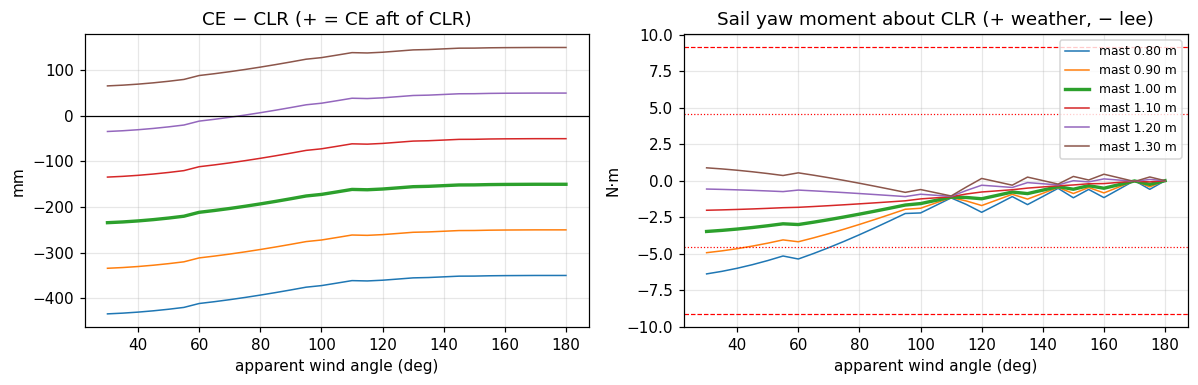

In [15]:
rows = []; curves = {}
for mx in (0.80, 0.90, 1.00, 1.10, 1.20, 1.30):
    s = helm_sweep(mx); curves[mx] = s
    lee = -s[s[:,0] >= 40, 2].min()
    up45 = s[s[:,0] == 45, 1][0]; run = s[-1, 1]
    rows.append([f"{mx:.2f}", f"{up45*1000:+.0f}", f"{run*1000:+.0f}" + (" (tracks)" if run < 0 else " **(unstable)**"),
                 f"{max(lee,0):.1f} N·m ({max(lee,0)/M_rud*100:.0f} %)"])
table(rows, ["Mast x (m)", "CE − CLR at 45° AWA (mm)", "CE − CLR running (mm)", "Max lee helm (% of rudder)"])

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for mx, s in curves.items():
    ax[0].plot(s[:,0], s[:,1]*1000, label=f"mast {mx:.2f} m", lw=2.2 if mx == 1.0 else 1)
    ax[1].plot(s[:,0], s[:,2], label=f"mast {mx:.2f} m", lw=2.2 if mx == 1.0 else 1)
ax[0].axhline(0, c='k', lw=.8); ax[0].set(title="CE − CLR (+ = CE aft of CLR)", xlabel="apparent wind angle (deg)", ylabel="mm")
for y in (M_rud, -M_rud): ax[1].axhline(y, c='r', ls='--', lw=.8)
for y in (M_rud/2, -M_rud/2): ax[1].axhline(y, c='r', ls=':', lw=.8)
ax[1].set(title="Sail yaw moment about CLR (+ weather, − lee)", xlabel="apparent wind angle (deg)", ylabel="N·m")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Reading the table.** The running CE is simply the mast position, because the plate is broadside and its CP is at mid-chord (on the axis). So the downwind rule reduces to **mast x < CLR x**. At 1.20 m the mast is behind the 1.15 m CLR estimate and the boat is unstable downwind. At 1.00 m there is a 150 mm margin, which also covers the CLR uncertainty band (1.12–1.23 m). Moving further forward buys little downwind but raises lee helm toward the rudder limit (dashed lines: 100 % and 50 % of capacity).

### 5.3 Packaging check at the chosen position
The drive (worm + motor, ~200 × 150 mm footprint) needs inside half-beam and depth. From Section 2:

In [16]:
x_hb = np.array(hh.xs); hb = np.array([hh.S[x][1][0] for x in hh.xs])
dep  = np.array([hh.S[x][0][1]-hh.section(x)[1] for x in hh.xs])
print(f"At x = {mast_x:.2f} m: max half-beam {np.interp(mast_x, x_hb, hb):.3f} m, keel-to-deck depth {np.interp(mast_x, x_hb, dep):.3f} m")
print(f"At x = 0.50 m: max half-beam {np.interp(0.5, x_hb, hb):.3f} m  (too narrow forward of ~0.5 m for a motor beside the mast)")
print(f"Height between bushings for the drive: ~{L_brg - 0.04 - 0.03 - 0.02:.3f} m  (L_brg minus ~40 mm deck bushing, ~30 mm heel bushing, ~20 mm clearance) [A]")

At x = 1.00 m: max half-beam 0.244 m, keel-to-deck depth 0.254 m
At x = 0.50 m: max half-beam 0.178 m  (too narrow forward of ~0.5 m for a motor beside the mast)
Height between bushings for the drive: ~0.136 m  (L_brg minus ~40 mm deck bushing, ~30 mm heel bushing, ~20 mm clearance) [A]


## 6. Rig mass and CG (for Luis: stability)

**Plate:** two faces (a 2 % allowance for the arc length over the chord), plus ribs/spine/bonds, plus core:
$$m_{sail} = m''_{skin}\cdot 2(1.02A)(1 + k_{rib}) + \rho_{foam} t_{core} A$$
**Mast** (thin-walled tube, from the heel bearing to 0.10 m below the tip):
$$m_{mast} = \rho_{cf}\,\frac{\pi}{4}(D_o^2 - D_i^2)\,L_{mast}$$
**CG height:**
$$z_{CG} = \frac{\sum m_i z_i}{\sum m_i}$$
with the sail at $z_{CE}$, the mast at its mid-length and the hardware at 0.1 m above the deck.

In [17]:
m_sail = skin_areal*2*1.02*A*(1+rib_frac) + foam_rho*core_t*A
L_mast = (z_tip - mast_top_below_tip) - z_heel
D_i    = mast_OD - 2*mast_wall
m_mast = rho_cf*math.pi/4*(mast_OD**2 - D_i**2)*L_mast
m_rig  = m_sail + m_mast + hardware_kg
z_rig  = (m_sail*z_CE + m_mast*(z_heel+L_mast/2) + hardware_kg*(z_deck+0.1))/m_rig
# rotational inertia about the mast (plate as a thin rectangle about its mid-chord + mast tube)
I_rot = m_sail*chord**2/12 + m_mast*(mast_OD**2 + D_i**2)/8
table([["Plate + spine + ribs", f"{m_sail:.2f} kg", f"@ {z_CE:+.2f} m"],
       ["Mast, CF {:.0f}×{:.1f}, L = {:.2f} m".format(mast_OD*1e3, mast_wall*1e3, L_mast), f"{m_mast:.2f} kg", f"@ {z_heel+L_mast/2:+.2f} m"],
       ["Hub, tip cap, fasteners", f"{hardware_kg:.2f} kg", f"@ {z_deck+0.1:+.2f} m"],
       ["**Total rotating mass**", f"**{m_rig:.2f} kg**", f"**CG {z_rig:+.2f} m above WL**"],
       ["Rotational inertia about mast", f"{I_rot:.3f} kg·m²", ""]], ["Item", "Mass", "Height"])

| Item | Mass | Height |
|---|---|---|
| Plate + spine + ribs | 1.24 kg | @ +0.76 m |
| Mast, CF 42×2.5, L = 1.18 m | 0.58 kg | @ +0.54 m |
| Hub, tip cap, fasteners | 0.50 kg | @ +0.28 m |
| **Total rotating mass** | **2.32 kg** | **CG +0.60 m above WL** |
| Rotational inertia about mast | 0.044 kg·m² |  |

## 7. Stability and the "full-power wind" (for Luis)

The heel constraint is expressed as the wind speed at which the sail's **maximum** force heels the boat to 20°. Above that wind the sail must be eased or feathered.

**System CG:**
$$KG = \frac{m_{bulb}z_{bulb} + m_{rig}z_{rig} + m_{other}z_{other}}{\Delta}$$

**Small-angle righting moment** [L8]:
$$GM = KM - KG, \qquad RM(\phi) \approx \Delta g\,GM\sin\phi$$

**Large-angle righting moment** from the full heeled-hull integration (`transatlantic_trade_sweep.B_curve`). The hull sections are rotated by φ, the waterline is re-found at constant displacement, and the lateral centre of buoyancy $B_y$ gives
$$GZ(\phi) = -z_G\sin\phi - B_y(\phi), \qquad RM = \Delta g\,GZ$$

**Full-power wind:** set the heeling moment equal to RM(20°):
$$q\,A\,C_{F,max}\,h_{heel} = RM_{20} \;\Rightarrow\; V_{fp} = \sqrt{\frac{2\,RM_{20}}{\rho_a\,A\,C_{F,max}\,h_{heel}}}$$

The heeling moment's cos²φ reduction is ignored at 20° (a 12 % effect), which is conservative.

In [18]:
KG = (bulb_kg*bulb_z + m_rig*z_rig + M_OTHER*Z_OTHER)/disp_kg
GM = KM_wl - KG
RM20_GM = disp_kg*g*GM*math.sin(math.radians(20))
V_fp = lambda RM: math.sqrt(2*RM/(rho_a*A*CF_max*h_heel))/kn

ev = ts.evaluate(span, chord, bulb_kg, -bulb_z)        # full GZ integration
print(f"KG = {KG:+.3f} m (wrt WL), GM = {GM:.3f} m")
print(f"RM(20°): GM method {RM20_GM:.1f} N·m -> full power to {V_fp(RM20_GM):.1f} kn")
print(f"RM(20°): GZ curve  {ev['RM20']:.1f} N·m -> full power to {ev['v_fp']:.1f} kn   <- used in the PDR numbers")
print(f"AVS (angle of vanishing stability) = {ev['AVS']:.0f}°  (deck assumed watertight)")

KG = -0.010 m (wrt WL), GM = 0.268 m
RM(20°): GM method 22.5 N·m -> full power to 13.8 kn
RM(20°): GZ curve  19.3 N·m -> full power to 12.8 kn   <- used in the PDR numbers
AVS (angle of vanishing stability) = 133°  (deck assumed watertight)


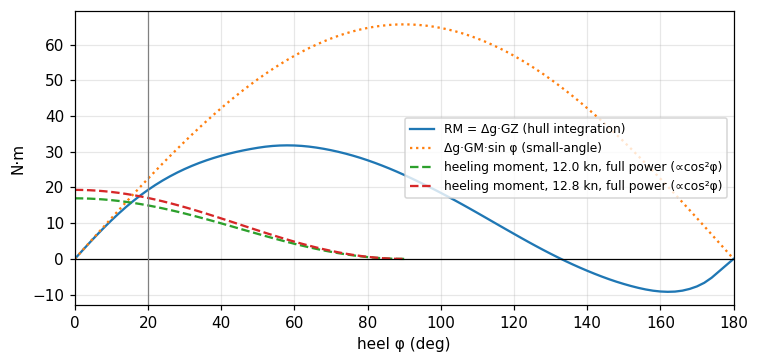

In [19]:
Bc = ts.B_curve(ev['disp']); zG = ts.WL_CAD + (M_OTHER*Z_OTHER + ev['rig']*ev['z_rig'] + bulb_kg*bulb_z)/ev['disp']
GZ = -zG*np.sin(np.radians(ts.ANG)) - Bc
phi = ts.ANG
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(phi, ev['disp']*g*GZ, label="RM = Δg·GZ (hull integration)")
ax.plot(phi, disp_kg*g*GM*np.sin(np.radians(phi)), ls=':', label="Δg·GM·sin φ (small-angle)")
for v in (V_cruise, ev['v_fp']):
    ax.plot(phi[phi <= 90], q(v)*A*CF_max*h_heel*np.cos(np.radians(phi[phi <= 90]))**2, ls='--', label=f"heeling moment, {v:.1f} kn, full power (∝cos²φ)")
ax.axhline(0, c='k', lw=.8); ax.axvline(20, c='gray', lw=.8)
ax.set(xlabel="heel φ (deg)", ylabel="N·m", xlim=(0, 180)); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

### 7.1 How much ballast does the sail actually need?
Solve $V_{fp}(m_{bulb}) = 12$ kn at 0.28 m bulb depth by bisection. This tells the keel team the minimum ballast the *sail* demands. Any extra is for survivability.

In [20]:
lo, hi = 2.0, 12.0
for _ in range(40):
    mid = (lo+hi)/2
    lo, hi = (mid, hi) if ts.evaluate(span, chord, mid, 0.28)['v_fp'] < 12 else (lo, mid)
e12 = ts.evaluate(span, chord, hi, 0.28)
print(f"Bulb for full power to 12 kn at 0.28 m: {hi:.1f} kg  (ballast ratio {hi/e12['disp']*100:.0f} %, displacement {e12['disp']:.1f} kg)")

Bulb for full power to 12 kn at 0.28 m: 5.5 kg  (ballast ratio 24 %, displacement 23.2 kg)


## 8. Load cases (for Luis, Sarah, Ava)

For each case, with the force applied at the CE of an upright boat:
$$F = q\,A\,C_F, \qquad M_{heel} = F\,h_{heel}, \qquad M_{deck} = F\,h_{mast}$$

**Wave-dunk case.** A breaking crest submerges the top 20 % of the sail at 1.5 m/s orbital velocity. Morison-type drag term [L10]:
$$F_w = \tfrac12\rho_w V_w^2\,C_D\,(0.2A), \qquad C_D = 1.2 \;[A]$$
It acts 0.12 m below the tip.

Why broadside is a real case for the plate: with a 50 % chord pivot, the cambered plate has no stable weathervane position. With the drive disengaged it rests roughly broadside (Design Decisions §3).

In [21]:
cases = [("Cruise 8 kn, full power", 8, CF_max), ("Cruise 12 kn, full power", 12, CF_max),
         ("20 kn, full power (upper bound)", 20, CF_max), ("27 kn, full power (upper bound)", 27, CF_max),
         ("27 kn, broadside", 27, CF_broad), (f"50 kn, feathered, ±{gust_yaw:.0f}° gust", 50, CF_feath),
         ("**50 kn, broadside (design case)**", 50, CF_broad)]
rows = []
for name, v, cf in cases:
    F = q(v)*A*cf
    rows.append([name, f"{q(v):.0f}", f"{cf:.2f}", f"{F:.0f}", f"{F*h_heel:.0f}", f"{F*h_mast:.0f}"])
F_s = q(V_survival)*A*CF_broad
V_w, CD_w, dunk = 1.5, 1.2, 0.2
F_w = 0.5*rho_w*V_w**2*CD_w*dunk*A
arm_w = z_tip - 0.12 - z_deck
rows.append([f"Wave dunk, top {dunk*100:.0f} % at {V_w} m/s", "—", f"{CD_w}", f"{F_w:.0f}", "—", f"{F_w*arm_w:.0f}"])
table(rows, ["Case", "q (Pa)", "C_F", "F (N)", "M_heel (N·m)", "M_deck (N·m)"])
M_lim = max(F_s*h_mast, F_w*arm_w); M_ult = SF*M_lim
print(f"Design mast-root moment: {M_lim:.0f} N·m limit / {M_ult:.0f} N·m ultimate;  shear {F_s:.0f} N")
v3 = 3.0; print(f"Check: a breaking wave at {v3} m/s would give {0.5*rho_w*v3**2*CD_w*dunk*A*arm_w:.0f} N·m -> exceeds design; handled by weather routing")

| Case | q (Pa) | C_F | F (N) | M_heel (N·m) | M_deck (N·m) |
|---|---|---|---|---|---|
| Cruise 8 kn, full power | 10 | 1.30 | 8 | 8 | 5 |
| Cruise 12 kn, full power | 23 | 1.30 | 19 | 17 | 11 |
| 20 kn, full power (upper bound) | 65 | 1.30 | 52 | 47 | 30 |
| 27 kn, full power (upper bound) | 118 | 1.30 | 95 | 86 | 55 |
| 27 kn, broadside | 118 | 1.35 | 98 | 89 | 57 |
| 50 kn, feathered, ±10° gust | 405 | 0.37 | 92 | 84 | 53 |
| **50 kn, broadside (design case)** | 405 | 1.35 | 338 | 306 | 194 |
| Wave dunk, top 20 % at 1.5 m/s | — | 1.2 | 171 | — | 159 |

Design mast-root moment: 194 N·m limit / 291 N·m ultimate;  shear 338 N
Check: a breaking wave at 3.0 m/s would give 636 N·m -> exceeds design; handled by weather routing


## 9. Mast tube

Thin-walled circular tube, cantilevered from the deck bearing [L9]:
$$I = \frac{\pi}{64}(D_o^4 - D_i^4), \qquad S = \frac{I}{D_o/2}, \qquad \sigma = \frac{M}{S}$$
Tip deflection at the CE for a point load (cantilever from the deck):
$$\delta = \frac{F\,h_{mast}^3}{3EI}$$
**Fatigue cycle count:** $N \approx t_{crossing}/T_{wave}$. The crossing takes 127 days (the C-Star PC13 MicroTransat crossing, 2026 [L11]). T ≈ 7 s is the typical trade-wind sea period [A].

In [22]:
I_m = math.pi/64*(mast_OD**4 - D_i**4); S_m = I_m/(mast_OD/2)
sigma_ult = M_ult/S_m
defl = F_s*h_mast**3/(3*E_mast*I_m)
N_cyc = 127*86400/7.0
print(f"I = {I_m:.3e} m^4, S = {S_m*1e6:.2f} cm^3")
print(f"σ_ult = {sigma_ult/1e6:.0f} MPa vs allowable {sigma_allow/1e6:.0f} MPa  -> margin {sigma_allow/sigma_ult:.1f}x")
print(f"Deflection at CE (limit, 50 kn broadside) = {defl*1000:.1f} mm")
print(f"Fatigue: ~{N_cyc/1e6:.1f} million wave cycles over 127 days")
# what OD would just meet the allowable (same wall)?
for OD in (0.030, 0.035, 0.038, 0.042):
    Di = OD-2*mast_wall; S_ = math.pi/64*(OD**4-Di**4)/(OD/2)
    print(f"   OD {OD*1000:.0f} x {mast_wall*1000:.1f}: σ_ult = {M_ult/S_/1e6:.0f} MPa")

I = 6.075e-08 m^4, S = 2.89 cm^3
σ_ult = 101 MPa vs allowable 400 MPa  -> margin 4.0x
Deflection at CE (limit, 50 kn broadside) = 3.5 mm
Fatigue: ~1.6 million wave cycles over 127 days
   OD 30 x 2.5: σ_ult = 212 MPa
   OD 35 x 2.5: σ_ult = 150 MPa
   OD 38 x 2.5: σ_ult = 125 MPa
   OD 42 x 2.5: σ_ult = 101 MPa


## 10. Bearing reactions (for Sarah, Ava)

The mast is a beam on two supports (deck and heel bushings) with an overhanging load. Taking moments about the deck bearing:
$$R_{heel} = \frac{M_{deck}}{L_{brg}}, \qquad R_{deck} = R_{heel} + F$$
Axial loads: slam $F_z = 3g\,m_{rig}$ down [A]; uplift ~60 N [A].

In [23]:
rows = []
for L in (0.15, L_brg, 0.30):
    Rh = M_lim/L; Rd = Rh + F_s
    rows.append([f"{L:.3f}" + (" (baseline)" if abs(L-L_brg) < 1e-6 else ""), f"{Rh:.0f} / {Rh*SF:.0f}", f"{Rd:.0f} / {Rd*SF:.0f}"])
table(rows, ["Bearing spacing (m)", "Heel bearing, limit / ult (N)", "Deck bearing, limit / ult (N)"])
print(f"Axial slam (3 g): {3*g*m_rig:.0f} N down")

| Bearing spacing (m) | Heel bearing, limit / ult (N) | Deck bearing, limit / ult (N) |
|---|---|---|
| 0.150 | 1295 / 1942 | 1633 / 2449 |
| 0.226 (baseline) | 861 / 1292 | 1199 / 1798 |
| 0.300 | 647 / 971 | 985 / 1478 |

Axial slam (3 g): 68 N down


## 11. Plate structure (spine and rib joints)

Ultimate panel pressure (broadside at 50 kn):
$$p_{ult} = SF\cdot q_{50}\,C_{F,broad}$$
Each half-chord cantilevers off the spine. Its root moment per metre of span is
$$m' = p_{ult}\frac{(c/2)^2}{2}$$
With ribs or brackets at spacing $s_r$, each joint carries $M_j = m' s_r$ and shear $V_j = p_{ult}(c/2)s_r$.

In [24]:
p_ult = SF*q(V_survival)*CF_broad
m_line = p_ult*(chord/2)**2/2
s_r = 0.30
print(f"p_ult = {p_ult:.0f} Pa;  m' = {m_line:.1f} N·m per m span")
print(f"Per joint at {s_r} m spacing: M = {m_line*s_r:.0f} N·m, V = {p_ult*chord/2*s_r:.0f} N  (4 ribs over {span} m span)")

p_ult = 820 Pa;  m' = 43.3 N·m per m span
Per joint at 0.3 m spacing: M = 13 N·m, V = 80 N  (4 ribs over 0.95 m span)


## 12. Drive torque (for Audrey): the binding constraint

Torque about the mast axis is the resultant force times its offset from the pivot, plus the camber couple:
$$T = q\,A\,c\left(\left|C_F\,(x_{cp} - a)\right| + |C_m|\right)$$
The two terms are added as **magnitudes**. In reality they partly cancel, so this is a conservative upper bound until CFD or a bench test gives the real moment curve.

Cases (Design Decisions §1 and §8):
- **Operating:** 27 kn, trimmed (C_F 0.35) or stalled (C_F,max with half the camber couple), plus a motion term $m_{sail}\,g\cdot 1g\cdot e_{cg}$ with $e_{cg}$ = 20 mm (CG offset from camber).
- **Survival hold:** 50 kn, drive locked, sail forced to 20–40° AoA by gusts or yaw. Take the larger of the feathered and mid-AoA cases.
- **Gearbox and end stops static:** $SF\times$ hold.

In [25]:
Cm = abs(Cm0)
def T(v, CF, cp, cm=0.0): return q(v)*A*chord*(abs(CF*(cp - pivot)) + abs(cm))
T_trim  = T(V_sail_max, 0.35, cp_small, Cm)
T_stall = T(V_sail_max, CF_max, cp_stall, 0.5*Cm)
T_motion= m_sail*g*1.0*0.02
T_op    = max(T_trim, T_stall) + T_motion
T_feath = T(V_survival, CF_feath, cp_small, Cm)
T_mid   = T(V_survival, CF_max, cp_stall, 0.5*Cm)
T_hold  = max(T_feath, T_mid)
T_static= SF*T_hold
table([["27 kn trimmed / stalled", f"{T_trim:.1f} / {T_stall:.1f}"], ["Motion (1 g roll, 20 mm CG offset)", f"{T_motion:.2f}"],
       ["**Operating**", f"**{T_op:.0f}**"], ["50 kn feathered ±10° / forced to mid-AoA", f"{T_feath:.0f} / {T_mid:.0f}"],
       ["**Survival hold (no slip)**", f"**{T_hold:.0f}**"], ["**Gearbox + end stops static (×1.5)**", f"**{T_static:.0f}**"],
       ["Last-move at 35 kn (operating × (35/27)²)", f"{T_op*(35/27)**2:.0f}"]], ["Case", "Torque (N·m)"])

| Case | Torque (N·m) |
|---|---|
| 27 kn trimmed / stalled | 15.2 / 18.3 |
| Motion (1 g roll, 20 mm CG offset) | 0.24 |
| **Operating** | **19** |
| 50 kn feathered ±10° / forced to mid-AoA | 53 / 63 |
| **Survival hold (no slip)** | **63** |
| **Gearbox + end stops static (×1.5)** | **94** |
| Last-move at 35 kn (operating × (35/27)²) | 31 |

### 12.1 Why chord and area are the levers
Every term in T is proportional to $q A c = q\,s\,c^2$. At fixed area, $c = \sqrt{A/AR}$, so
$$T \propto A\,c = \frac{A^{3/2}}{\sqrt{AR}}$$
The hold torque is steep in area (power 1.5) and weak in aspect ratio (power −0.5). Meanwhile the mast moment and heel grow with span ($\propto A\,(z_{foot} + s/2)$). The plot shows the fixed-area trade that led to AR ≈ 1.5 (Design Decisions §4.3).

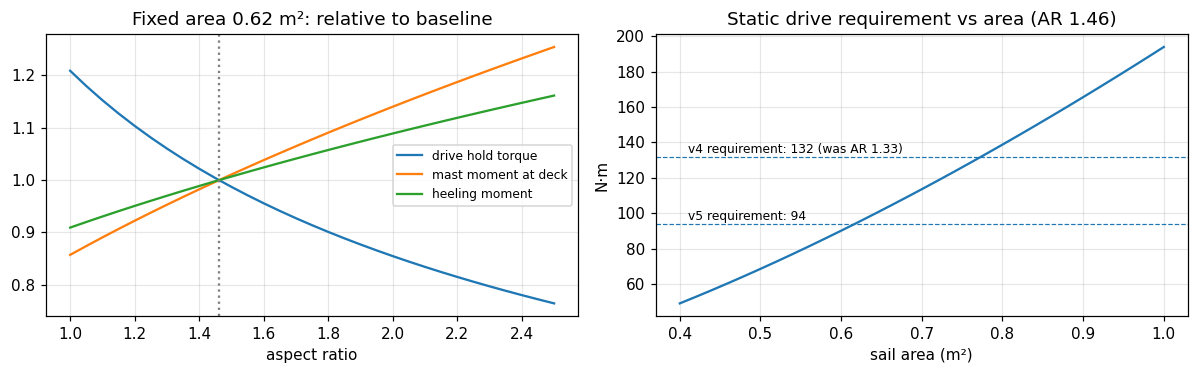

AR 1.5 -> 2.0 at fixed area: hold -13%, Mdeck +13%, Mheel +8%


In [26]:
def metrics(s, c):
    A_ = s*c; zce = z_foot + s/2
    hold = q(V_survival)*A_*c*(abs(CF_max*(cp_stall-pivot)) + 0.5*Cm)
    return dict(hold=hold, Mdeck=q(V_survival)*A_*CF_broad*(zce-z_deck), Mheel=q(V_cruise)*A_*CF_max*(zce+CLR_depth))
base = metrics(span, chord)
ARs = np.linspace(1.0, 2.5, 31); A0 = A
res = {k: [] for k in base}
for ar in ARs:
    c_ = math.sqrt(A0/ar); m = metrics(ar*c_, c_)
    for k in m: res[k].append(m[k]/base[k])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for k, lab in (("hold","drive hold torque"),("Mdeck","mast moment at deck"),("Mheel","heeling moment")): ax[0].plot(ARs, res[k], label=lab)
ax[0].axvline(AR, c='gray', ls=':'); ax[0].set(title=f"Fixed area {A0:.2f} m²: relative to baseline", xlabel="aspect ratio"); ax[0].legend(fontsize=8)
Aa = np.linspace(0.4, 1.0, 31)
ax[1].plot(Aa, [SF*q(V_survival)*a_*math.sqrt(a_/AR)*(abs(CF_max*(cp_stall-pivot))+0.5*Cm) for a_ in Aa])
for y, lab in ((94,"v5 requirement: 94"),(132,"v4 requirement: 132 (was AR 1.33)")): ax[1].axhline(y, ls='--', lw=.8); ax[1].text(0.41, y+2, lab, fontsize=8)
ax[1].set(title=f"Static drive requirement vs area (AR {AR:.2f})", xlabel="sail area (m²)", ylabel="N·m"); plt.tight_layout(); plt.show()
i15, i20 = np.argmin(abs(ARs-1.5)), np.argmin(abs(ARs-2.0))
print("AR 1.5 -> 2.0 at fixed area: " + ", ".join(f"{k} {res[k][i20]/res[k][i15]-1:+.0%}" for k in res))

### 12.2 Gearbox check against catalog data [L13]
Catalog **continuous** output ratings at 1,400 rpm input, service factor 1. The hold is a static load, and static capacity is normally well above continuous. Treating continuous as the holding limit therefore builds in margin. Self-locking generally needs static efficiency < 50 %, i.e. a small lead angle and a high ratio [L14].

With a final spur or chain stage of ratio $i_f$ on the mast, the worm sees $T_{hold}/i_f$ (ignoring the final stage's efficiency, which is conservative for holding).

In [27]:
catalog = {"NMRV030": {60: 19, 80: 14}, "NMRV040": {60: 43, 80: 34, 100: 38}, "NMRV050": {60: 89, 80: 72, 100: 60}}
rows = []
for size, rat in catalog.items():
    for i, Tc in rat.items():
        for i_f in (1, 2, 3):
            need = T_hold/i_f
            if Tc >= need: rows.append([size, i, f"{Tc}", f"{i_f}:1", f"{need:.0f}", f"{Tc/need:.2f}"])
table(rows, ["Worm size", "worm ratio", "continuous (N·m)", "final stage", "worm sees in hold (N·m)", "margin"])

| Worm size | worm ratio | continuous (N·m) | final stage | worm sees in hold (N·m) | margin |
|---|---|---|---|---|---|
| NMRV040 | 60 | 43 | 2:1 | 31 | 1.37 |
| NMRV040 | 60 | 43 | 3:1 | 21 | 2.06 |
| NMRV040 | 80 | 34 | 2:1 | 31 | 1.08 |
| NMRV040 | 80 | 34 | 3:1 | 21 | 1.63 |
| NMRV040 | 100 | 38 | 2:1 | 31 | 1.21 |
| NMRV040 | 100 | 38 | 3:1 | 21 | 1.82 |
| NMRV050 | 60 | 89 | 1:1 | 63 | 1.42 |
| NMRV050 | 60 | 89 | 2:1 | 31 | 2.84 |
| NMRV050 | 60 | 89 | 3:1 | 21 | 4.26 |
| NMRV050 | 80 | 72 | 1:1 | 63 | 1.15 |
| NMRV050 | 80 | 72 | 2:1 | 31 | 2.30 |
| NMRV050 | 80 | 72 | 3:1 | 21 | 3.44 |
| NMRV050 | 100 | 60 | 2:1 | 31 | 1.91 |
| NMRV050 | 100 | 60 | 3:1 | 21 | 2.87 |

### 12.3 Motor power and daily energy
$$P_{mech} = T_{op}\,\omega, \qquad P_{el} = P_{mech}/\eta, \qquad \omega = \frac{\pi}{t_{180}}$$
$$E_{day} = \left(\frac{n_{trim}\theta_{trim} + n_{tack}\cdot 180°}{\dot\theta}\right)P_{el} + P_{standby}\cdot 86{,}400\text{ s}$$

In [28]:
for t180, eta in ((20, 0.25), (10, 0.25), (180/slew_deg_s, eta_drive)):
    w = math.pi/t180; Pm = T_op*w
    print(f"180° in {t180:4.0f} s, η = {eta:.2f}: P_mech = {Pm:4.1f} W, P_el = {Pm/eta:4.1f} W")
w = math.radians(slew_deg_s); P_el = T_op*w/eta_drive
t_move = (trims_per_day*trim_deg + tacks_per_day*180)/slew_deg_s
E_day = t_move*P_el + standby_W*86400
print(f"Moving time {t_move:.0f} s/day -> {t_move*P_el/3600:.2f} Wh; standby {standby_W*24:.1f} Wh; total ≈ {E_day/3600:.1f} Wh/day")
i_tot = 20*50*2
print(f"Motor torque at an overall ratio of {i_tot}:1 (20:1 gearmotor × 50:1 worm × 2:1 final), η = {eta_drive}: T_motor = T_op/(i·η) = {T_op/(i_tot*eta_drive)*1000:.0f} mN·m")

180° in   20 s, η = 0.25: P_mech =  2.9 W, P_el = 11.6 W
180° in   10 s, η = 0.25: P_mech =  5.8 W, P_el = 23.3 W
180° in   10 s, η = 0.30: P_mech =  5.8 W, P_el = 19.4 W
Moving time 180 s/day -> 0.97 Wh; standby 2.4 Wh; total ≈ 3.4 Wh/day
Motor torque at an overall ratio of 2000:1 (20:1 gearmotor × 50:1 worm × 2:1 final), η = 0.3: T_motor = T_op/(i·η) = 31 mN·m


## 13. Summary for other subsystems

In [29]:
table([
 ["Area / AR / section", f"{A:.2f} m² / {AR:.2f} / 8 % arc, R {R_arc:.2f} m", "Luis, Sarah, Preesha"],
 ["Tip / CE / foot / deck above WL", f"{z_tip:+.2f} / {z_CE:+.2f} / {z_foot:+.2f} / {z_deck:+.2f} m", "Luis, Megan"],
 ["Mast axis", f"{mast_x:.2f} m from bow, centreline", "Ava, hull"],
 ["Sweep circle on deck", f"Ø {2*R_sweep:.2f} m, x {mast_x-R_sweep:.3f}–{mast_x+R_sweep:.3f} m", "Preesha, Jonah, Nav"],
 ["Rig mass @ CG", f"{m_rig:.1f} kg @ {z_rig:+.2f} m", "Luis"],
 ["RM(20°) / full power until (7 kg @ 0.28 m)", f"{ev['RM20']:.1f} N·m / {ev['v_fp']:.1f} kn", "Luis"],
 ["Ballast for full power to 12 kn", f"~{hi:.1f} kg @ 0.28 m", "Luis"],
 ["50 kn broadside force", f"{F_s:.0f} N", "Sarah, Ava"],
 ["Mast moment at deck, limit / ult", f"{M_lim:.0f} / {M_ult:.0f} N·m", "Sarah, Ava"],
 ["Bearings heel / deck (limit, {:.3f} m)".format(L_brg), f"{M_lim/L_brg:.0f} / {M_lim/L_brg+F_s:.0f} N", "Sarah, Ava"],
 ["Drive operating / hold / static", f"{T_op:.0f} / {T_hold:.0f} / ≥ {T_static:.0f} N·m", "Audrey"],
 ["Energy", f"~{E_day/3600:.1f} Wh/day", "Nav/ECE, Preesha"],
 ["Max lee helm (12 kn, placeholder rudder)", f"{-curves[1.0][curves[1.0][:,0]>=40,2].min():.1f} N·m of {M_rud:.1f} capacity", "Megan"],
], ["Quantity", "Value", "Who needs it"])

| Quantity | Value | Who needs it |
|---|---|---|
| Area / AR / section | 0.62 m² / 1.46 / 8 % arc, R 1.04 m | Luis, Sarah, Preesha |
| Tip / CE / foot / deck above WL | +1.23 / +0.76 / +0.28 / +0.18 m | Luis, Megan |
| Mast axis | 1.00 m from bow, centreline | Ava, hull |
| Sweep circle on deck | Ø 0.65 m, x 0.675–1.325 m | Preesha, Jonah, Nav |
| Rig mass @ CG | 2.3 kg @ +0.60 m | Luis |
| RM(20°) / full power until (7 kg @ 0.28 m) | 19.3 N·m / 12.8 kn | Luis |
| Ballast for full power to 12 kn | ~5.5 kg @ 0.28 m | Luis |
| 50 kn broadside force | 338 N | Sarah, Ava |
| Mast moment at deck, limit / ult | 194 / 291 N·m | Sarah, Ava |
| Bearings heel / deck (limit, 0.226 m) | 861 / 1199 N | Sarah, Ava |
| Drive operating / hold / static | 19 / 63 / ≥ 94 N·m | Audrey |
| Energy | ~3.4 Wh/day | Nav/ECE, Preesha |
| Max lee helm (12 kn, placeholder rudder) | 3.3 N·m of 9.1 capacity | Megan |

## 14. Cross-check against `transatlantic_sail_sizing.py`
The original script should reproduce Sections 3–12 exactly. If this cell prints `MISMATCH`, one of the two has drifted.

In [30]:
import io, contextlib, transatlantic_sail_sizing as tss
buf = io.StringIO()
with contextlib.redirect_stdout(buf): r = tss.run("plate")
checks = {"Mast M_deck lim/ult": (r['M'], f"{M_lim:.0f} / {M_ult:.0f} N.m"), "hold": (r['hold'], f"{T_hold:.0f} N.m"),
          "static": (r['static'], f"{T_static:.0f} N.m"), "Top": (r['Top'], f"{T_op:.0f} N.m"),
          "50 kn broadside": (r['Fs'], f"{F_s:.0f} N"), "mass": (r['mass'], f"{m_rig:.1f} kg @ {z_rig:.2f} m"),
          "energy": (r['E'], f"{E_day/3600:.1f} Wh/d")}
for k, (a_, b_) in checks.items(): print(f"{k:22s} script: {a_:>18s}   notebook: {b_:>18s}   {'ok' if a_ == b_ else 'MISMATCH'}")

Mast M_deck lim/ult    script:      194 / 291 N.m   notebook:      194 / 291 N.m   ok
hold                   script:             63 N.m   notebook:             63 N.m   ok
static                 script:             94 N.m   notebook:             94 N.m   ok
Top                    script:             19 N.m   notebook:             19 N.m   ok
50 kn broadside        script:              338 N   notebook:              338 N   ok
mass                   script:    2.3 kg @ 0.60 m   notebook:    2.3 kg @ 0.60 m   ok
energy                 script:           3.4 Wh/d   notebook:           3.4 Wh/d   ok


## Appendix A. PDR alternative: NACA 0015 foil, pivot at 20 % chord

Same planform, heights and hull. What changes:
- The CP sits just aft of the pivot, so the foil **weathervanes**. A slip clutch can be the survival mode.
- It has no camber couple ($C_{m0}$ = 0 for a symmetric section [L3]).
- Its C_L,max at Re ~2×10⁵ is lower (~0.9–1.0) because of early laminar separation [L5].
- The pivot at 20 % chord gives a bigger sweep circle.

The numbers below come from the same script (`run("foil")`), so the two columns use identical methods. The helm check reuses the Section 5 model with the foil tables.

In [31]:
buf = io.StringIO()
with contextlib.redirect_stdout(buf): rp, rf = tss.run("plate"), tss.run("foil")
keys = [("pivot","Pivot"),("sweep","Sweep dia"),("mass","Rotating mass @ CG"),("vol","Sealed volume"),("vlim","Full power until (GM method)"),
        ("Fs","50 kn broadside force"),("M","Mast M_deck lim/ult"),("brg","Bearings heel/deck (limit)"),("Top","Operating torque"),
        ("hold","Hold (plate) / clutch slip (foil)"),("static","Gearbox + stops static"),("E","Energy")]
table([[n, rp[k], rf[k]] for k, n in keys], ["", "Plate (baseline)", "NACA 0015 foil"])
FOIL = dict(CL=interp(FOIL_CL), CD=interp(FOIL_CD), cpS=0.25, cpB=0.45, pivot=0.20, plate=False)
for mx in (0.90, 1.00):
    s = helm_sweep(mx, V=FOIL)
    print(f"Foil, mast {mx:.2f} m: CE−CLR at 45° {s[s[:,0]==45,1][0]*1000:+.0f} mm, running {s[-1,1]*1000:+.0f} mm, max lee helm {max(0,-s[s[:,0]>=40,2].min()):.1f} N·m")

|  | Plate (baseline) | NACA 0015 foil |
|---|---|---|
| Pivot | 50% chord | 20% chord |
| Sweep dia | 0.65 m | 1.04 m |
| Rotating mass @ CG | 2.3 kg @ 0.60 m | 2.0 kg @ 0.58 m |
| Sealed volume | 0 L | 41 L |
| Full power until (GM method) | 14 kn | 15 kn |
| 50 kn broadside force | 338 N | 300 N |
| Mast M_deck lim/ult | 194 / 291 N.m | 173 / 259 N.m |
| Bearings heel/deck (limit) | 862 / 1200 N | 767 / 1067 N |
| Operating torque | 19 N.m | 8 N.m |
| Hold (plate) / clutch slip (foil) | 63 N.m | 17 N.m |
| Gearbox + stops static | 94 N.m | 34 N.m |
| Energy | 3.4 Wh/d | 2.8 Wh/d |

Foil, mast 0.90 m: CE−CLR at 45° -180 mm, running -246 mm, max lee helm 5.0 N·m


Foil, mast 1.00 m: CE−CLR at 45° -80 mm, running -146 mm, max lee helm 4.8 N·m


## 15. References and source tags

**Team sources [M]/[T]**
- [M] `Box/26-27/Transatlantic Hull 26-27/Transatlantic Hull Shell.SLDPRT` (9/14, jy962), section geometry transcribed in `hull_hydrostatics_from_cad.py`
- [T] Hull review slides (Jason, Skyler): 25 kg displacement, "subject to change"
- [T] Keel (Luis): 7 kg bulb at ~0.28 m, rough. CLR not yet drawn.
- [T] Rudder (Megan): 0.10 × 0.17 m at x ≈ 2.06 m, placeholder

**Literature [L]**
- [L1] ISO 2533:1975, *Standard Atmosphere* (ρ = 1.225 kg/m³ at sea level). Seawater 1025 kg/m³: ITTC Recommended Procedure 7.5-02-01-03, *Fresh Water and Seawater Properties*.
- [L2] Beaufort wind force scale: UK Met Office, https://weather.metoffice.gov.uk/guides/coast-and-sea/beaufort-scale ; NOAA WPC, https://www.wpc.ncep.noaa.gov/html/beaufort.shtml
- [L3] J. D. Anderson, *Fundamentals of Aerodynamics*, ch. 4 (thin-airfoil theory, cambered airfoil: α_L=0, C_m,c/4) and ch. 5 (finite wings). Helmbold's relation as given in J. D. Anderson, *Aircraft Performance and Design*, eq. 2.18a.
- [L4] A. Bruining, *Aerodynamic characteristics of a curved plate airfoil section at Reynolds numbers 60,000 and 100,000 and angles of attack from −10 to +90 degrees*, TU Delft report, 1979. https://repository.tudelft.nl/record/uuid:6b92442a-01f7-4b7c-8d53-c4f10720ff3e
- [L5] A. Pelletier & T. J. Mueller, "Low Reynolds Number Aerodynamics of Low-Aspect-Ratio, Thin/Flat/Cambered-Plate Wings," *J. Aircraft*, 2000. https://doi.org/10.2514/2.2676
- [L6] S. F. Hoerner, *Fluid-Dynamic Drag*, 1965, ch. 3 (flat plates normal to flow; hollow/cup shapes).
- [L7] Typical CFRP laminate density ~1,550–1,600 kg/m³ (any composites handbook, e.g. ASM Handbook vol. 21).
- [L8] L. Larsson, R. Eliasson & M. Orych, *Principles of Yacht Design* (hydrostatics, GM/GZ, SA/D, sail-plan balance and CE–CLR lead). Rudder C_L,max ≈ 0.8 for a low-AR foil below stall.
- [L9] R. C. Hibbeler, *Mechanics of Materials* (flexure formula, cantilever deflection).
- [L10] J. R. Morison et al., "The force exerted by surface waves on piles," *Petroleum Transactions AIME*, 1950 (drag term ½ρC_D A V²).
- [L11] Oshen C-Star PC13 MicroTransat crossing, 7 May – 13 Sep 2026, 127 days, 2,926 nmi; the 2025 attempt was lost when a storm destroyed the sail. Yacht.de, https://www.yacht.de/en/yachts/small-cruiser/microtransat-challenge-c-star-pc13-became-the-first-autonomous-robotic-boat-to-cross-the-atlantic/ ; Smart Maritime Network, https://smartmaritimenetwork.com/2026/09/16/oshen-autonomous-vessel-completes-first-unaided-atlantic-crossing/
- [L12] Diab Divinycell H60 technical data (nominal density 60 kg/m³).
- [L13] Worm gearbox catalogs: Finer PT worm gearbox catalogue (finerpt.com); StepperOnline NMRV40 page (omc-stepperonline.com); RS Components listing, Motovario NMRV040 100:1 (rs-online.com).
- [L14] "Self-locking in worm gears," Motion Control Tips, https://www.motioncontroltips.com/when-are-worm-gears-self-locking-and-where-is-this-useful/

**Assumptions [A] most likely to move the answer** (ranked by effect on the binding drive constraint):
1. Plate C_m and CP location, which set hold torque directly
2. The magnitude-sum in the torque formula (conservative)
3. The CLR position (sets the mast position margin)
4. The CF tube allowable and modulus
5. Skin areal mass (sets rig mass and CG)